![](https://media.tenor.com/3gEEz-BC6EgAAAAM/unraisinable-raisins.gif)

In [25]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score,StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,ConfusionMatrixDisplay

In [26]:
df = pd.read_csv('../../00-data/raisin.csv')

### **Voting vs. Stacking Classifiers**

| Feature | **Voting Classifier** | **Stacking Classifier** |
| :--- | :--- | :--- |
| **Main Idea** | Combines model predictions directly using a simple rule. | Trains a "meta-model" to learn how to best combine predictions. |
| **Decision Logic** | **Hard Voting:** Majority wins. <br> **Soft Voting:** Average of probabilities. | **Meta-learning:** The final estimator learns which base models are most reliable. |
| **Output Type** | Direct aggregation (Mean or Mode). | A new prediction generated by the meta-model. |
| **Analogy** | **Democratic:** Everyone gets a vote; the majority/average wins. | **Hierarchical:** An expert (manager) reviews everyone's input to make the call. |
| **Best Used When...** | Base models have similar performance levels. | You want to capture complex patterns in how base models succeed or fail. |


### **KNN and Support Vector Classifier**
| Model | Core Logic | Best Used When... |
| :--- | :--- | :--- |
| **KNN** | Majority vote of $k$ nearest points. | Dataset is small and has simple patterns. |
| **SVC** | Maximizing the margin between classes. | You have high-dimensional data or clear margins. |

---

In [10]:
df.columns

Index(['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity',
       'ConvexArea', 'Extent', 'Perimeter', 'Class'],
      dtype='object')

In [11]:
df.Class.value_counts()

Class
Kecimen    450
Besni      450
Name: count, dtype: int64

In [15]:
X = df.drop('Class',axis=1)
y = df['Class'].map({'Kecimen':0,'Besni':1})

In [17]:
X_train,X_test,y_train,y_test = train_test_split(X,y,
                                                 test_size=0.2,
                                                 random_state=13)

In [24]:
log_pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('lrc',LogisticRegression()),
])
knn_pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('knn',KNeighborsClassifier()),
])
svc_pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('svc',SVC()),
])
dtc_pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('dtc',DecisionTreeClassifier()),
])
rf_pipeline= Pipeline([
    ('scaler',StandardScaler()),
    ('rfc',RandomForestClassifier()),
])

base_models = {
    'logreg':log_pipeline,
    'knn':knn_pipeline,
    'svc':svc_pipeline,
    'dtc':dtc_pipeline,
    'rf':rf_pipeline
}

## Benchmarking each base model with 5- fold cv

In [33]:
cv = StratifiedKFold(shuffle=True,random_state=12)

base_score = {}
for name,model in base_models.items():
    scores = cross_val_score(model,X_train,y_train,cv=cv,scoring='accuracy')
    base_score[name] = scores
    print(f"{name:13s} mean={scores.mean():.4f} std={scores.std():.4f}")

logreg        mean=0.8653 std=0.0336
knn           mean=0.8389 std=0.0330
svc           mean=0.8736 std=0.0344
dtc           mean=0.7958 std=0.0083
rf            mean=0.8611 std=0.0228


In [34]:
import seaborn as sns

<Axes: >

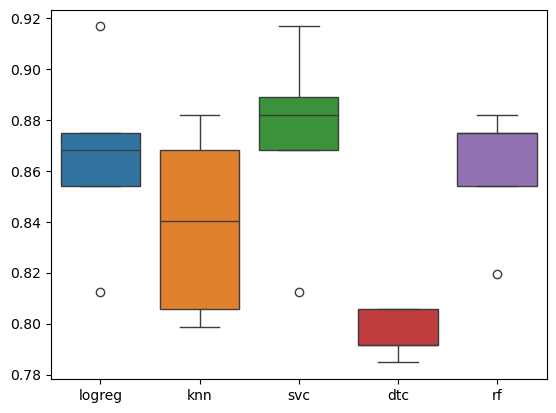

In [35]:
cv_df = pd.DataFrame(base_score)
sns.boxplot(data=cv_df)

## Voting Classifier

In [66]:
voters_hard = [
    ('logreg',log_pipeline),
    ('knn',knn_pipeline),
    ('svc',svc_pipeline),
    ('dtc',dtc_pipeline),
    ('rf',rf_pipeline)
]

voters_soft = [
    ('logreg',log_pipeline),
    ('knn',knn_pipeline),
    # ('svc',svc_pipeline),
    ('dtc',dtc_pipeline),
    ('rf',rf_pipeline)
]

In [67]:
hard_vote = VotingClassifier(estimators=voters_hard)
soft_vote = VotingClassifier(estimators=voters_soft,voting='soft')

In [68]:
hard_vote.fit(X_train,y_train)

,estimators,"[('logreg', ...), ('knn', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False


In [69]:
soft_vote.fit(X_train,y_train)

,estimators,"[('logreg', ...), ('knn', ...), ...]"
,voting,'soft'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False


In [70]:
y_pred_hard = hard_vote.predict(X_test)

In [71]:
y_pred_soft = soft_vote.predict(X_test)

In [72]:
print(classification_report(y_test,y_pred_hard))

              precision    recall  f1-score   support

           0       0.89      0.89      0.89        98
           1       0.87      0.87      0.87        82

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



In [73]:
print(classification_report(y_test,y_pred_soft))

              precision    recall  f1-score   support

           0       0.90      0.87      0.89        98
           1       0.85      0.89      0.87        82

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



## Stacking Classifier

In [74]:
stack = StackingClassifier(estimators=voters_hard,
                           final_estimator=LogisticRegression(),
                          cv=cv,
                          n_jobs=-1)

In [75]:
stack.fit(X_train,y_train)

,estimators,"[('logreg', ...), ('knn', ...), ...]"
,final_estimator,LogisticRegression()
,cv,StratifiedKFo... shuffle=True)
,stack_method,'auto'
,n_jobs,-1
,passthrough,False
,verbose,0
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'


In [76]:
y_pred_stack = stack.predict(X_test)

In [78]:
print(classification_report(y_test,y_pred_stack))

              precision    recall  f1-score   support

           0       0.89      0.85      0.87        98
           1       0.83      0.88      0.85        82

    accuracy                           0.86       180
   macro avg       0.86      0.86      0.86       180
weighted avg       0.86      0.86      0.86       180



In [80]:
df['Class'].unique()

array(['Kecimen', 'Besni'], dtype=object)

In [83]:
import matplotlib.pyplot as plt


----hard_voting----
              precision    recall  f1-score   support

     Kecimen       0.89      0.87      0.88        98
       Besni       0.85      0.87      0.86        82

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



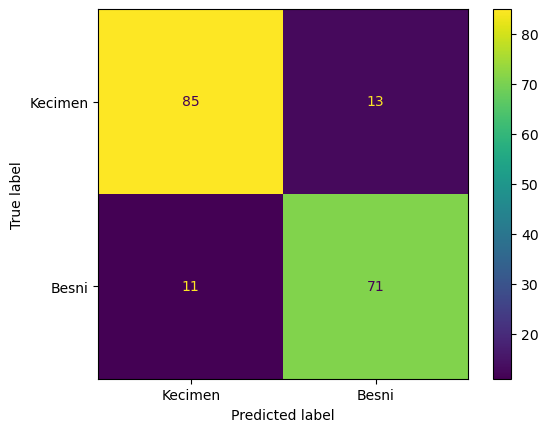

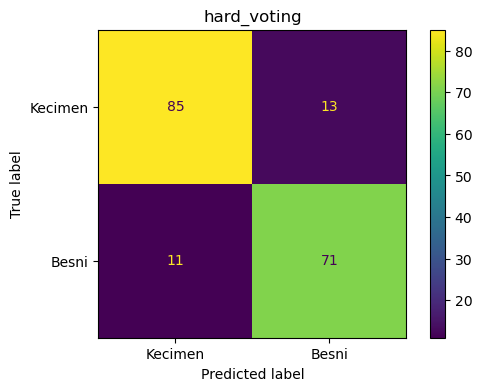


----soft_voting----
              precision    recall  f1-score   support

     Kecimen       0.89      0.86      0.88        98
       Besni       0.84      0.88      0.86        82

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



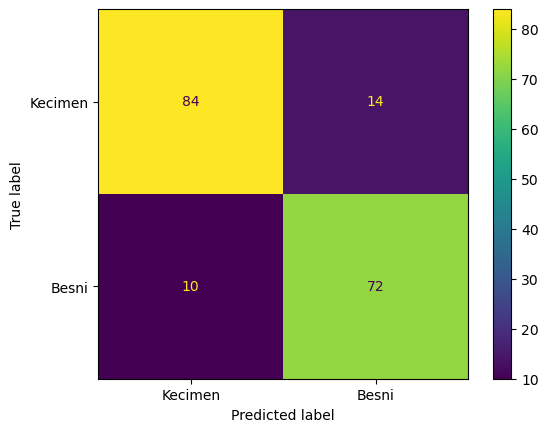

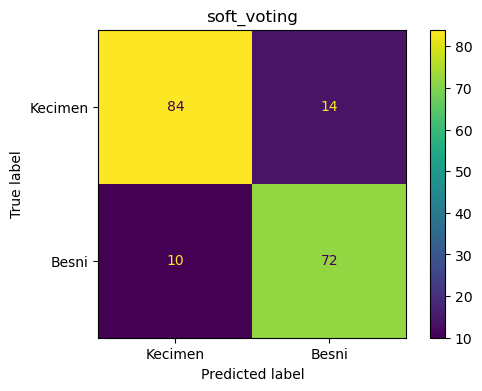


----stack----
              precision    recall  f1-score   support

     Kecimen       0.90      0.88      0.89        98
       Besni       0.86      0.88      0.87        82

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



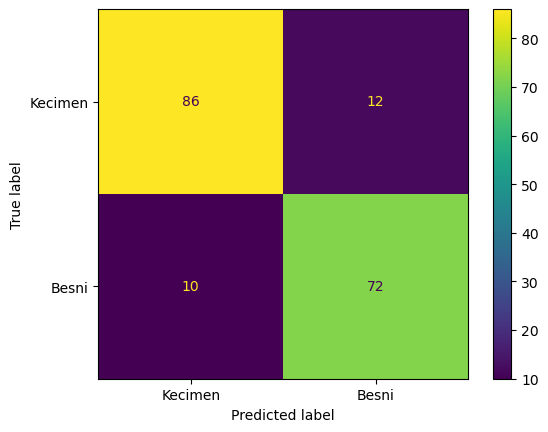

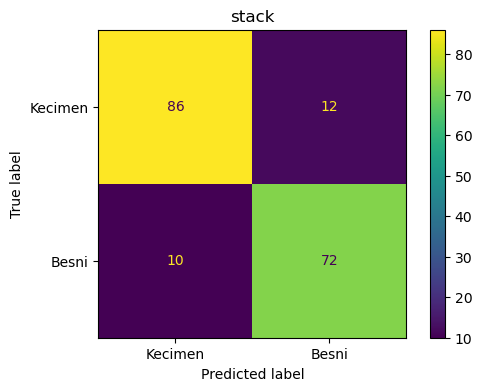

In [86]:
final_models = {
    'hard_voting': hard_vote, 
    'soft_voting':soft_vote,
    'stack':stack
}

results = {}

for name, model in final_models.items():
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    results[name] = accuracy_score(y_test,y_pred)
    print(f"\n----{name}----")
    print(classification_report(y_test,y_pred,target_names=['Kecimen', 'Besni']))
    disp = ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['Kecimen', 'Besni'])
    fig,axe = plt.subplots(figsize=(6,4))
    disp.plot(ax=axe)
    axe.set_title(f"{name}")
    plt.show()

In [88]:
# for name, model in final_models.items():
#     model.fit(X_train,y_train)
#     y_pred = model.predict(X_test)
#     results[name] = accuracy_score(y_test,y_pred)
#     print(f"\n----{name}----")
#     # print(classification_report(y_test,y_pred,target_names=['Kecimen', 'Besni']))
#     disp = ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['Kecimen', 'Besni'])
#     fig,axe = plt.subplots(figsize=(6,4))
#     disp.plot(ax=axe)
#     axe.set_title(f"{name}")
#     plt.show()

In [89]:
# not an actual exam, open book, wifi allowed, if you want the help of best friend also i think can (not encouraged)

In [90]:
df = pd.read_csv('../../00-data/bank_marketing2.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   client_id                   38159 non-null  float64
 1   age                         40305 non-null  float64
 2   job                         39223 non-null  object 
 3   marital                     38819 non-null  object 
 4   education                   39408 non-null  object 
 5   credit_default              41188 non-null  object 
 6   mortgage                    41188 non-null  object 
 7   month                       41188 non-null  object 
 8   day                         41188 non-null  int64  
 9   contact_duration            41188 non-null  int64  
 10  number_contacts             41188 non-null  int64  
 11  previous_campaign_contacts  40149 non-null  float64
 12  previous_outcome            41188 non-null  object 
 13  cons_price_idx              398

In [91]:
df = pd.read_csv('../../00-data/bank_marketing2.csv')
df.info('../../00-data/SET_A_employees.csv')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   client_id                   38159 non-null  float64
 1   age                         40305 non-null  float64
 2   job                         39223 non-null  object 
 3   marital                     38819 non-null  object 
 4   education                   39408 non-null  object 
 5   credit_default              41188 non-null  object 
 6   mortgage                    41188 non-null  object 
 7   month                       41188 non-null  object 
 8   day                         41188 non-null  int64  
 9   contact_duration            41188 non-null  int64  
 10  number_contacts             41188 non-null  int64  
 11  previous_campaign_contacts  40149 non-null  float64
 12  previous_outcome            41188 non-null  object 
 13  cons_price_idx              398

In [ ]:
df.drop_duplicates()